# ARIMA Time Series Analysis — Ready-to-Teach Notebook

**Audience:** beginners with basic pandas knowledge  
**Goal:** learn the ARIMA workflow from data loading to forecasting and evaluation.

## Learning outcomes
By the end of this notebook, students should be able to:
1. explain what ARIMA means,
2. test stationarity,
3. difference a time series,
4. fit an ARIMA model,
5. make forecasts,
6. evaluate forecast performance,
7. explain why seasonality often needs SARIMA.


## What ARIMA means

ARIMA stands for:

- **AR** = AutoRegressive  
  The model uses past values of the series.

- **I** = Integrated  
  The series is differenced to make it more stationary.

- **MA** = Moving Average  
  The model uses past forecast errors.

We write the model as **ARIMA(p, d, q)**:

- `p`: number of AR lags
- `d`: number of differences
- `q`: number of MA lags


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA


## Load the shampoo sales dataset

This dataset is small and easy for teaching because students can focus on:
- trend,
- differencing,
- ARIMA fitting,
- forecast evaluation.

It is a good first ARIMA dataset before moving to seasonal data.


In [3]:
df = pd.read_csv('../../00-data/shampoo.csv')
df['Month'] = pd.to_datetime(df['Month'])
df = df.set_index('Month')

df.head()


,Sales
Month,
2001-01-01,266.0
2001-02-01,145.9
2001-03-01,183.1
2001-04-01,119.3
2001-05-01,180.3


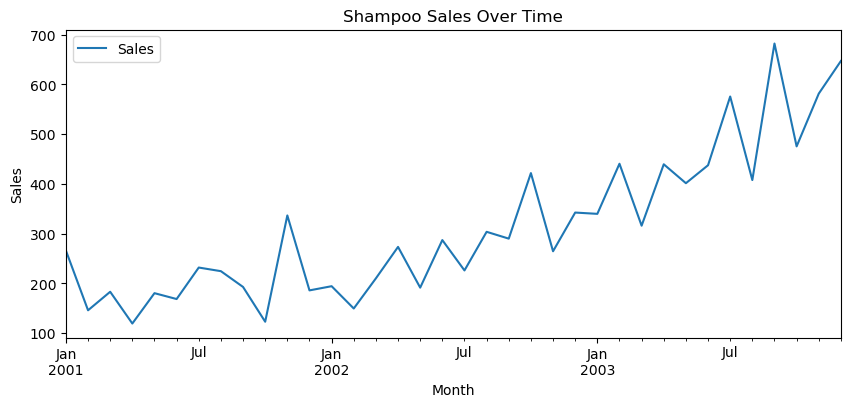

In [4]:
df.plot(figsize=(10, 4), title='Shampoo Sales Over Time')
plt.ylabel('Sales')
plt.show()


## Explain the first plot

The series appears to have an upward movement over time.
That suggests the raw series may not be stationary.

A stationary series usually has:
- roughly constant mean,
- roughly constant variance,
- no strong trend over time.

ARIMA often works better after the series is made stationary.


## Train-test split

We keep the last 6 observations for testing.
This lets students evaluate whether the model generalizes to unseen future values.


In [5]:
train = df.iloc[:-6]
test = df.iloc[-6:]

print('Train shape:', train.shape)
print('Test shape:', test.shape)
train.tail(), test.head()


Train shape: (30, 1)
Test shape: (6, 1)


(            Sales
 Month            
 2003-02-01  440.4
 2003-03-01  315.9
 2003-04-01  439.3
 2003-05-01  401.3
 2003-06-01  437.4,
             Sales
 Month            
 2003-07-01  575.5
 2003-08-01  407.6
 2003-09-01  682.0
 2003-10-01  475.3
 2003-11-01  581.3)

## ADF test for stationarity

The Augmented Dickey-Fuller test checks whether a series likely has a unit root.

### Rule of thumb
- **p-value < 0.05**: evidence that the series is stationary
- **p-value >= 0.05**: not enough evidence of stationarity


In [6]:
result = adfuller(train['Sales'])

print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:')
for key, value in result[4].items():
    print(f'  {key}: {value}')


ADF Statistic: 0.4873059070996354
p-value: 0.9844821197389604
Critical Values:
  1%: -3.7112123008648155
  5%: -2.981246804733728
  10%: -2.6300945562130176


## Differencing the series

If the series is not stationary, one common solution is **first differencing**.

This calculates:

\[
y'_t = y_t - y_{t-1}
\]

This removes much of the trend and often makes the series more stable.


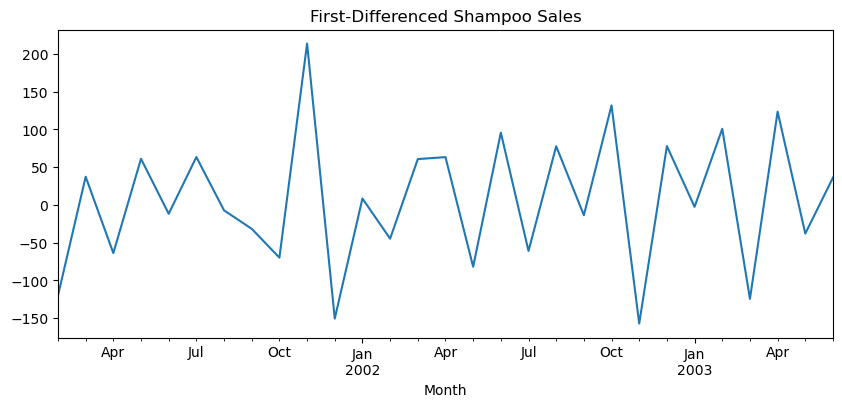

In [7]:
train_diff = train['Sales'].diff().dropna()

train_diff.plot(figsize=(10, 4), title='First-Differenced Shampoo Sales')
plt.show()


In [8]:
diff_result = adfuller(train_diff)

print('ADF Statistic after differencing:', diff_result[0])
print('p-value after differencing:', diff_result[1])


ADF Statistic after differencing: -6.426524057680065
p-value after differencing: 1.7390606693039247e-08


## ACF and PACF plots

These plots help us think about possible values for `p` and `q`.

- **ACF** helps us inspect possible MA behaviour
- **PACF** helps us inspect possible AR behaviour

For teaching, these are heuristic tools, not magic rules.


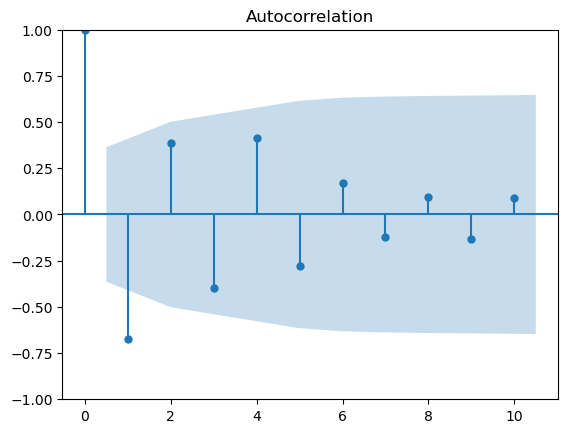

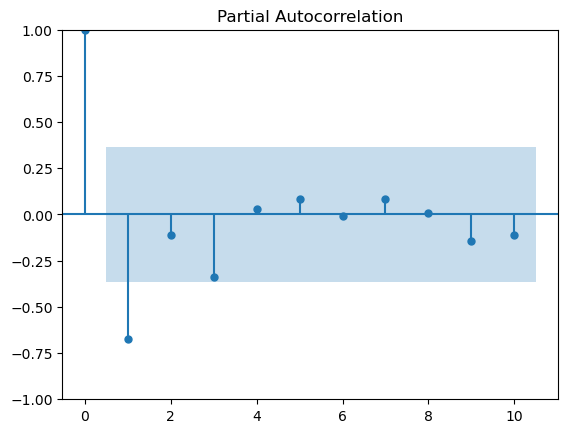

In [9]:
plot_acf(train_diff, lags=10)
plt.show()

plot_pacf(train_diff, lags=10, method='ywm')
plt.show()


## Fit a simple ARIMA model

We will try **ARIMA(1,1,1)**:
- `p=1`
- `d=1`
- `q=1`

This is a common starter model for teaching.


In [10]:
model = ARIMA(train['Sales'], order=(1, 1, 1))
model_fit = model.fit()

print(model_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   30
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -161.746
Date:                Thu, 12 Mar 2026   AIC                            329.492
Time:                        17:05:03   BIC                            333.594
Sample:                    01-01-2001   HQIC                           330.777
                         - 06-01-2003                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4926      0.305     -1.617      0.106      -1.090       0.104
ma.L1         -0.3821      0.264     -1.447      0.148      -0.900       0.136
sigma2      3991.0438   1145.462      3.484      0.0

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


## Forecast the test period

We forecast the same number of steps as the size of the test set.


In [11]:
forecast = model_fit.forecast(steps=len(test))
forecast.index = test.index

forecast


Month
2003-07-01    406.875552
2003-08-01    421.912724
2003-09-01    414.505005
2003-10-01    418.154249
2003-11-01    416.356532
2003-12-01    417.242136
Name: predicted_mean, dtype: float64

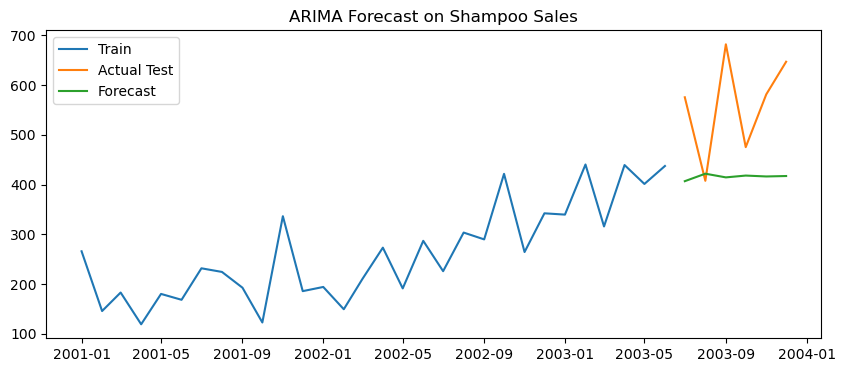

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(train.index, train['Sales'], label='Train')
plt.plot(test.index, test['Sales'], label='Actual Test')
plt.plot(forecast.index, forecast, label='Forecast')
plt.title('ARIMA Forecast on Shampoo Sales')
plt.legend()
plt.show()


## Evaluate the forecast

We use:
- **MAE**: average absolute error
- **RMSE**: penalizes larger errors more strongly

Smaller values are better.


In [13]:
mae = mean_absolute_error(test['Sales'], forecast)
rmse = mean_squared_error(test['Sales'], forecast) ** 0.5

print('MAE :', round(mae, 3))
print('RMSE:', round(rmse, 3))


MAE : 150.363
RMSE: 174.837


## Why not just use one ARIMA order?

ARIMA modelling usually involves trying several combinations of `(p,d,q)` and comparing them.

In teaching, start simple:
1. test stationarity,
2. difference if needed,
3. inspect ACF/PACF,
4. fit a few candidate models,
5. compare forecast errors.


## Optional mini model comparison

This cell lets students compare several small ARIMA models.


In [14]:
orders = [(1,1,0), (1,1,1), (2,1,1), (2,1,2)]
results = []

for order in orders:
    try:
        m = ARIMA(train['Sales'], order=order).fit()
        pred = m.forecast(steps=len(test))
        pred.index = test.index
        mae = mean_absolute_error(test['Sales'], pred)
        rmse = mean_squared_error(test['Sales'], pred) ** 0.5
        results.append({'order': order, 'AIC': m.aic, 'MAE': mae, 'RMSE': rmse})
    except Exception as e:
        results.append({'order': order, 'AIC': None, 'MAE': None, 'RMSE': None})

pd.DataFrame(results).sort_values('RMSE')


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be use

,order,AIC,MAE,RMSE
0,"(1, 1, 0)",328.804833,146.944179,170.572656
1,"(1, 1, 1)",329.492170,150.363208,174.836757
2,"(2, 1, 1)",331.360611,151.613751,176.307175
3,"(2, 1, 2)",331.860116,159.832226,185.708191


# Second dataset: airline passengers

This dataset is useful because it shows strong seasonality.
That gives a teaching moment:

**Plain ARIMA may struggle when clear seasonal patterns exist.**
That is where **SARIMA** becomes important.


In [17]:
air = pd.read_csv('../../00-data/Airline.csv')
air['Month'] = pd.to_datetime(air['Month'])
air = air.set_index('Month')

air.head()


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


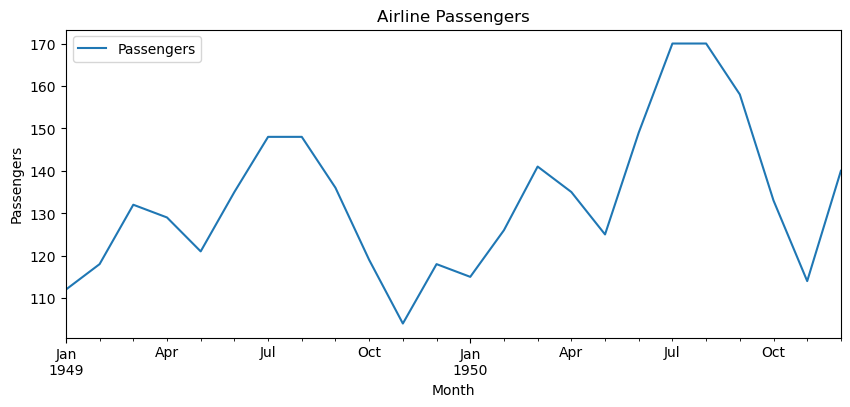

In [18]:
air.plot(figsize=(10, 4), title='Airline Passengers')
plt.ylabel('Passengers')
plt.show()


## Teaching point on seasonality

Notice the repeated rise-and-fall pattern over time.
That repeating pattern is seasonality.

A plain ARIMA model does not explicitly model seasonal structure.
So this dataset is excellent for explaining why the next topic after ARIMA is usually **SARIMA**.


# Exercises for students

## Exercise 1
Run the ADF test on the airline passengers dataset.  
Is it stationary?

## Exercise 2
Difference the airline passengers series once and plot it.

## Exercise 3
Try fitting `ARIMA(1,1,1)` to the airline data and observe the forecast.

## Exercise 4
Try two more ARIMA orders and compare AIC.

## Exercise 5
Explain in your own words why SARIMA would probably be a better choice for the airline dataset.


# Summary

In this lesson, we learned how to:
- read a time series dataset,
- visualize the series,
- test stationarity using ADF,
- difference the series,
- inspect ACF and PACF,
- fit an ARIMA model,
- make forecasts,
- evaluate forecasts,
- recognize when seasonality suggests SARIMA instead.
